In [14]:
import numpy as np
import matplotlib.pyplot as plt


02.09.26
Trying to solve problem 1.3 and 1.4 numerically, from the notes given by Mats. 

1.3:
The heat equation
$$ u_t = u_{xx} $$
is the simplest example of a dissipative equation. 

a) What is the "dispersive relation" for the heat eq?

b) Show that $\frac{d}{dt} ||u||_{L^2(\mathbb{R})} < 0 $ for all nontrivial $u(t,\cdot) \in H^2(\mathbb{R})$,and that the corresponding devay is exponential for solutions in $C^2_{per}(\mathbb{R})$.

c) Find the solution for the heat eq. given initial data $u_0 \in C^\infty_0(\mathbb{R}) $. For general initial-data, what does this say about the regularity, support and long-time behaviour? Recalla Fourier transform of a Gaussian



In [15]:
# a) From the analytical solution, we have that the dispersion relation is pruly imaginary. 
# IOT show this here we use the test solution u(x,t) = exp(i(kx - wt)) 
# and solve the differential equation using FDM.
def spatial_double_derivative(u, dx):
    return (np.roll(u, -1) - 2 * u + np.roll(u, 1)) / dx**2 

def time_step(u, dt , dx):
    return u + dt * spatial_double_derivative(u, dx)

def f(x, t, k, w):
    return np.exp(1j * (k * x - w * t))

Numerical Im(omega): -9.0093
Continuum -k^2: -9.0000
Discrete symbol: -8.9933


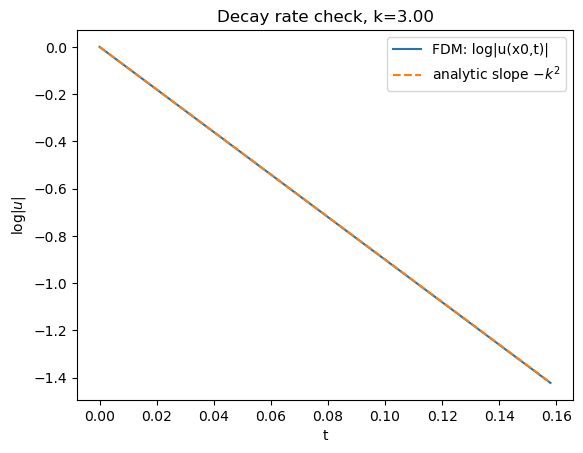

In [22]:
N = 200
L = np.pi * 2

#solving the differential equation using FDM
x = np.linspace(0, L, N , endpoint=False)
dx = x[1] - x[0]
dt = 0.4*dx**2
nsteps = 400
t_arr = np.arange(nsteps+1) * dt

m = 3
k = 2 * np.pi * m / L

u = f(x, 0, k, 0)

amp = np.zeros(nsteps +1)
amp[0] = np.abs(u[0])

for n in range(nsteps):
    u = time_step(u, dt, dx)
    amp[n + 1] = np.abs(u[0])


mask = amp > 1e-10
slope, _ = np.polyfit(t_arr[mask], np.log(amp[mask]), 1)

print(f"Numerical Im(omega): {slope:.4f}") # numerical slope of the log|u| decay
print(f"Continuum -k^2: {-k**2:.4f}") # analytic slope of the equation
print(f"Discrete symbol: {-4*np.sin(k*dx/2)**2/dx**2:.4f}") # analytic slope of the scheme


plt.plot(t_arr, np.log(amp), label='FDM: log|u(x0,t)|')
plt.plot(t_arr, np.log(amp[0]) - k**2 * t_arr, '--', label=r'analytic slope $-k^2$')
plt.xlabel('t'); plt.ylabel(r'$\log|u|$')
plt.legend(); plt.title(f'Decay rate check, k={k:.2f}')
plt.show()

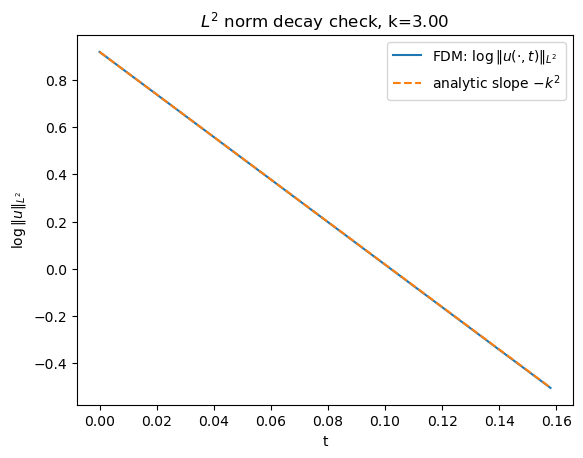

In [23]:
#b) to show that the dime derivative of u is negative we can simply compute the L^2 norm
# for each time step and use the forward time derivative to show that it is negative. 

U = np.zeros((nsteps + 1, N), dtype=complex)
U[0, :] = f(x, 0, k, 0)

l2_norm = np.zeros(nsteps + 1)
l2_norm[0] = np.linalg.norm(U[0])*np.sqrt(dx)

for n in range(nsteps):
    U[n + 1, :] = time_step(U[n, :], dt, dx)
    l2_norm[n + 1] = np.linalg.norm(U[n + 1]) * np.sqrt(dx)


mask = l2_norm > 1e-10
slope, _ = np.polyfit(t_arr[mask], np.log(l2_norm[mask]), 1)


plt.plot(t_arr, np.log(l2_norm), label=r'FDM: $\log\|u(\cdot,t)\|_{L^2}$')
plt.plot(t_arr, np.log(l2_norm[0]) - k**2 * t_arr, '--', label=r'analytic slope $-k^2$')
plt.xlabel('t'); plt.ylabel(r'$\log\|u\|_{L^2}$')
plt.legend(); plt.title(f'$L^2$ norm decay check, k={k:.2f}')
plt.show()

C:\Users\henri\AppData\Local\Temp\ipykernel_14448\3835736181.py:6: RuntimeWarning: divide by zero encountered in divide
  return np.exp(-1/(1-x**2)) * (np.abs(x) < 1)


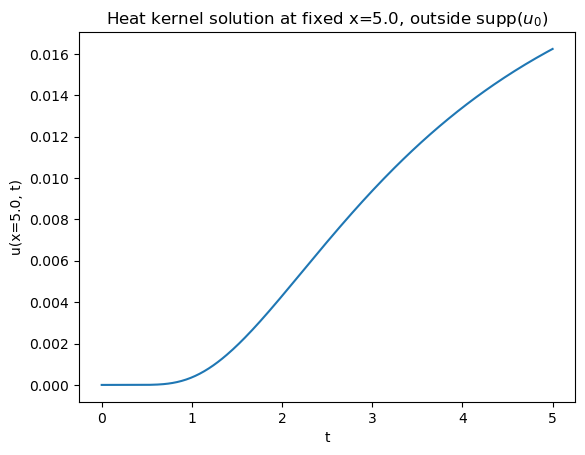

In [38]:
# c) Find the solution to the heat equation. 
# For this we choose u(x,0) as a bump function, and fix x_0 iot. use the
# Heat kernel and numerical integration to find the solution.

def bump_function(x):
    return np.exp(-1/(1-x**2)) * (np.abs(x) < 1)

def heat_kernel(x, t):
    return 1/np.sqrt(4*np.pi*t) * np.exp(-x**2/(4*t))



Ny = 4000
L = 10
y = np.linspace(-L, L, Ny, endpoint=False)
dy = y[1] - y[0]
u0 = bump_function(y)

def u_at(x0,t):
    G = heat_kernel(x0 - y, t)
    return np.trapz(G * u0, y)



x0 = 5.0   # note: this is OUTSIDE supp(u0) = (-2,2) !
t_arr = np.linspace(1e-3, 5, 300)
u_vals = np.array([u_at(x0, t) for t in t_arr])

plt.plot(t_arr, u_vals)
plt.xlabel('t')
plt.ylabel(f'u(x={x0}, t)')
plt.title(f'Heat kernel solution at fixed x={x0}, outside supp($u_0$)')
plt.show()

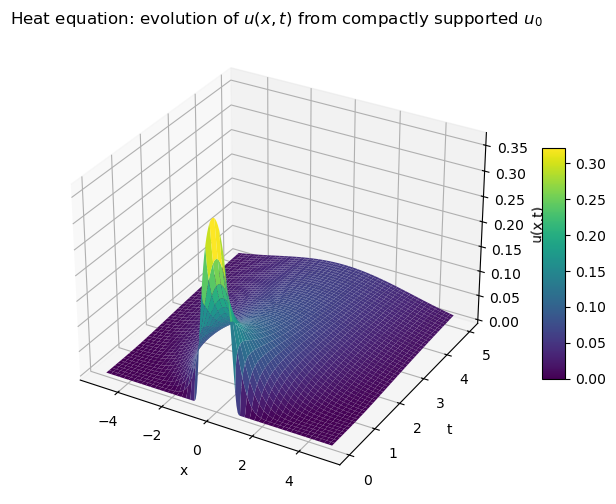

In [39]:
from mpl_toolkits.mplot3d import Axes3D

x_plot = np.linspace(-5, 5, 200)
t_plot = np.linspace(1e-3, 5, 200)
X,T = np.meshgrid(x_plot, t_plot)

U = np.zeros_like(X)
for i,t in enumerate(t_plot):
    G = heat_kernel(X[i,:] - y[:,None], t)
    U[i,:] = np.trapz(G * u0[:,None], y, axis=0)

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, T, U, cmap='viridis', linewidth=0, antialiased=True)
ax.set_xlabel('x')
ax.set_ylabel('t')
ax.set_zlabel('u(x,t)')
ax.set_title('Heat equation: evolution of $u(x,t)$ from compactly supported $u_0$')
fig.colorbar(surf, shrink=0.5, aspect=10)
plt.show()

1.4:
The Airy equation is the linear ordinary differential equation
$$ y{\xi \xi} - \xi y = 0 $$
Show that is $y(\xi)$ is a smooth solution of the Airy eq. then 
$$ u(t,x):= \frac{y(\xi)}{t^{1/3}}, \quad \xi:= \frac{x}{(3t)^{1/3}} $$
Solves the linear KdV equation for $t>0$. 

$$ u_t = u_{xxx} $$